# P02. Operadores básicos

## Objetivo: Utilizar diferentes operadores para facilitar el procesamiento complejo de imágenes.

## Instrucciones

### a) aplique los siguientes operadores a una imagen
* Aumento/Disminución de brillo..
* Copiado.
* Negativo.
* Aclarado/Oscurecimiento.
* Elongación/Reduccin de Contraste.
* Shifting H/V/D.

### Importacion de librerias

In [2]:
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import os
from IPython.display import display, HTML

#### Conversión a escala de grises

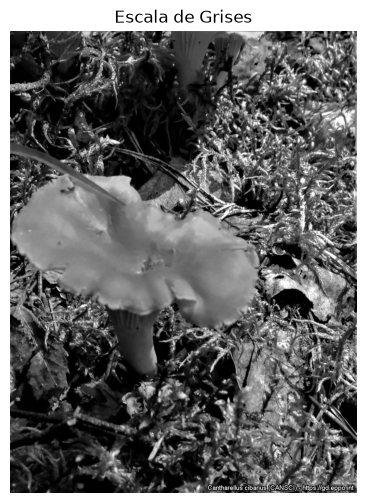

In [7]:
# Cargar la imagen original
imagen_bgr = cv2.imread('Imagenes/Entrada/Cantharellus cibarius(CANSCI).jpg')
# Convertir la imagen a escala de grises
imagen_gris = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2GRAY)
# Mostrar la imagen en escala de grises
plt.figure(figsize=(8, 6))
plt.imshow(imagen_gris, cmap='gray')
plt.title('Escala de Grises')
plt.axis('off') # Ocultar los ejes
plt.show()

Descargar Imagen y Matriz en escala de grises y la tupla original con los valores RGB

In [10]:
# 1. Descargar (guardar) la imagen en escala de grises como archivo JPG
cv2.imwrite('Imagenes/Salida/imagen_gris_descargada.jpg', imagen_gris)

# 2. Descargar la matriz en escala de grises (guardándola como archivo CSV)
# Usamos fmt='%d' para guardar los valores como enteros (0-255)
np.savetxt('Matrices/Salida/matriz_gris.csv', imagen_gris, delimiter=',', fmt='%d')

# 3. Obtener la tupla original con los valores RGB
# Nota: cv2 carga las imágenes en formato BGR, por lo que la convertimos a RGB
imagen_rgb = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)

# La "tupla" en imágenes hace referencia a las dimensiones (Alto, Ancho, Canales)
tupla_original_rgb = imagen_rgb.shape

imagen_rgb = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)

matriz_rgb_2d = imagen_rgb.reshape(imagen_rgb.shape[0], -1)

np.savetxt('Matrices/Entrada/matriz_original_rgb.csv', matriz_rgb_2d, delimiter=',', fmt='%d')

print("Matriz original RGB generada y descargada correctamente.")

print("Imagen y matriz en escala de grises guardadas correctamente.")
print(f"Tupla original de la imagen RGB (Alto, Ancho, Canales): {tupla_original_rgb}")

Matriz original RGB generada y descargada correctamente.
Imagen y matriz en escala de grises guardadas correctamente.
Tupla original de la imagen RGB (Alto, Ancho, Canales): (1365, 1024, 3)


#### Definicion de la funcion de aumento y disminucion de ruido

In [14]:
def operador_brillo(imagen, B, operacion):
    """
    Modifica el brillo de una imagen en escala de grises.
    operacion: 'aumento' o 'disminucion'
    """
    # Convertimos a int16 para evitar desbordamiento en las operaciones
    P = imagen.astype(np.int16)
    
    if operacion == 'aumento':
        # Q(X,Y) = P(X,Y) + B
        Q = P + B 
    elif operacion == 'disminucion':
        # Q(X,Y) = P(X,Y) - B
        Q = P - B 
    else:
        raise ValueError("La operación debe ser 'aumento' o 'disminucion'")
    
    # Mantenemos los valores en el rango [0, 255]
    Q = np.clip(Q, 0, 255)
    
    return Q.astype(np.uint8)

#### Ejecucion y Resultados 

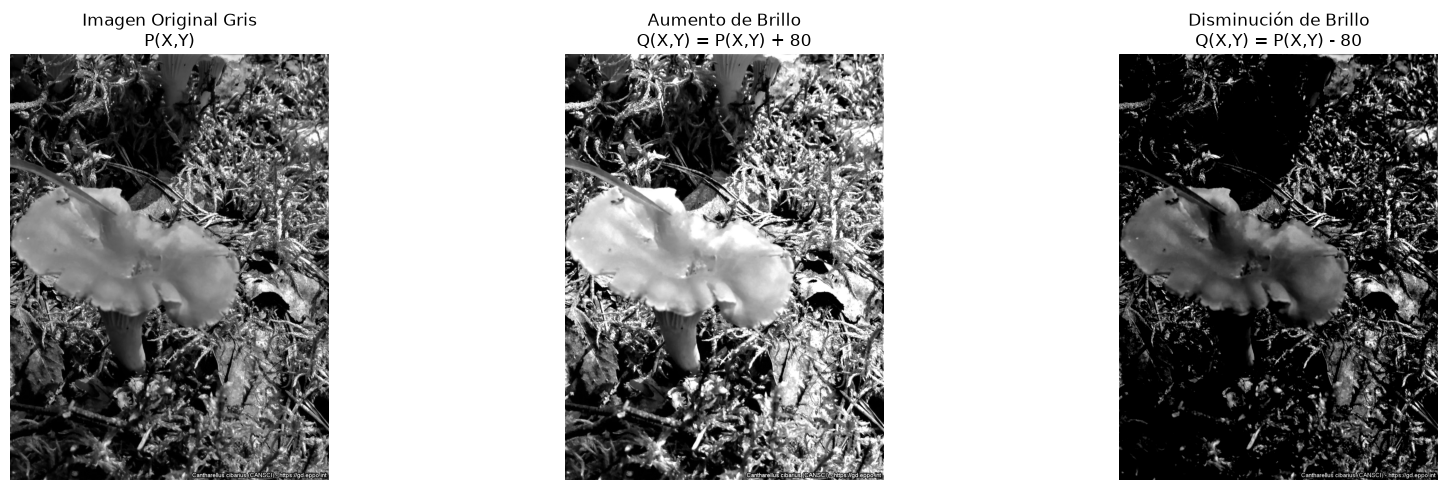

In [15]:
# Definir la constante B
B = 80

# 1. Aumento de brillo
imagen_aclarada_gris = operador_brillo(imagen_gris, B, operacion='aumento')

# 2. Disminución de brillo
imagen_oscurecida_gris = operador_brillo(imagen_gris, B, operacion='disminucion')

# --- Mostrar los resultados ---
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# Usamos cmap='gray' para visualizar correctamente la escala de grises
axs[0].imshow(imagen_gris, cmap='gray')
axs[0].set_title('Imagen Original Gris\nP(X,Y)')
axs[0].axis('off')

axs[1].imshow(imagen_aclarada_gris, cmap='gray')
axs[1].set_title(f'Aumento de Brillo\nQ(X,Y) = P(X,Y) + {B}') #[cite: 1]
axs[1].axis('off')

axs[2].imshow(imagen_oscurecida_gris, cmap='gray')
axs[2].set_title(f'Disminución de Brillo\nQ(X,Y) = P(X,Y) - {B}') #[cite: 1]
axs[2].axis('off')

plt.tight_layout()
plt.show()

Descarga de Imagenes y matrices

In [44]:
# --- 1. Guardar las imágenes procesadas (formato PNG para no perder calidad) ---
cv2.imwrite('Imagenes/Salida/imagen_aumento_brillo.png', imagen_aclarada_gris)
cv2.imwrite('Imagenes/Salida/imagen_Disminucion_brillo.png', imagen_oscurecida_gris)
print("Imágenes guardadas correctamente.")

# --- 2. Guardar las matrices de píxeles en formato CSV ---
# delimiter=',' separa los valores por comas, y fmt='%d' los guarda como enteros
np.savetxt('Matrices/Salida/matriz_aumento_brillo.csv', imagen_aclarada_gris, delimiter=',', fmt='%d')
np.savetxt('Matrices/Salida/matriz_Disminucion_brillo.csv', imagen_oscurecida_gris, delimiter=',', fmt='%d')
print("Matrices CSV guardadas correctamente.")

Imágenes guardadas correctamente.
Matrices CSV guardadas correctamente.


#### Declaración de la Función de Copiado

In [19]:
def operador_copiado(imagen_matriz_p):
    """
    Aplica el operador de copiado a una imagen.
    De acuerdo con la fórmula: ∀x,y Q(x,y) = P(x,y)
    """
    # En numpy, usamos np.copy() para asegurar que creamos una matriz nueva Q(x,y)
    # independiente en memoria, pero con los mismos valores exactos que P(x,y)
    imagen_matriz_q = np.copy(imagen_matriz_p)
    
    return imagen_matriz_q

#### Ejecución y Visualización

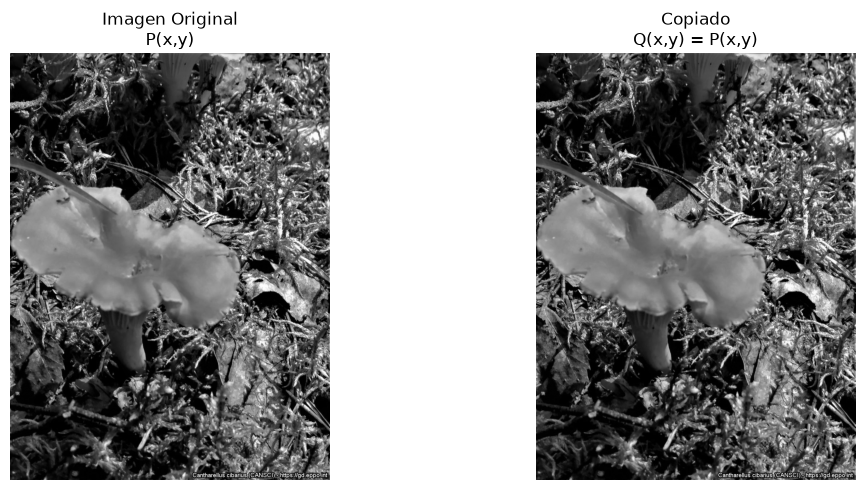

In [21]:
# 1. Cargar una imagen de prueba directamente en escala de grises
img_entrada_p = cv2.imread('./Imagenes/Salida/imagen_gris_descargada.jpg', cv2.IMREAD_GRAYSCALE)

# 2. Aplicar el operador de copiado
img_salida_q = operador_copiado(img_entrada_p)

# --- 3. Mostrar los resultados ---
# Esta vez usamos 1 fila y 2 columnas ya que solo comparamos la original y la copia
fig_copiado, axs_copiado = plt.subplots(1, 2, figsize=(12, 5))

axs_copiado[0].imshow(img_entrada_p, cmap='gray')
axs_copiado[0].set_title('Imagen Original\nP(x,y)')
axs_copiado[0].axis('off')

axs_copiado[1].imshow(img_salida_q, cmap='gray')
axs_copiado[1].set_title('Copiado\nQ(x,y) = P(x,y)') 
axs_copiado[1].axis('off')

plt.tight_layout()
plt.show()

In [22]:
# --- 1. Guardar las imágenes generadas (Formato PNG) ---
cv2.imwrite('Imagenes/Salida/resultado_operador_copia.png', img_salida_q)
print("Imágenes del proceso de copiado listas y guardadas.")

# --- 2. Guardar las matrices numéricas (Formato CSV) ---
# Se guardan como enteros ('%d') para observar los valores de los píxeles (0-255)
np.savetxt('Matrices/Salida/matriz_q_copia.csv', img_salida_q, delimiter=',', fmt='%d')
print("Matrices CSV del proceso de copiado listas y guardadas.")

Imágenes del proceso de copiado listas y guardadas.
Matrices CSV del proceso de copiado listas y guardadas.


#### Declaración de la Función del Operador Negativo

In [25]:
def operador_negativo(matriz_pixel_p):
    """
    Aplica el operador negativo a una imagen.
    De acuerdo con la fórmula: ∀x,y Q(x,y) = 255 - P(x,y)
    """
    # Convertimos a int16 por buena práctica para operar matrices
    matriz_p = matriz_pixel_p.astype(np.int16)
    
    # Aplicamos la fórmula del negativo
    matriz_q = 255 - matriz_p
    
    # Aseguramos límites y retornamos en uint8
    matriz_q = np.clip(matriz_q, 0, 255)
    
    return matriz_q.astype(np.uint8)

#### Ejecución y Visualización

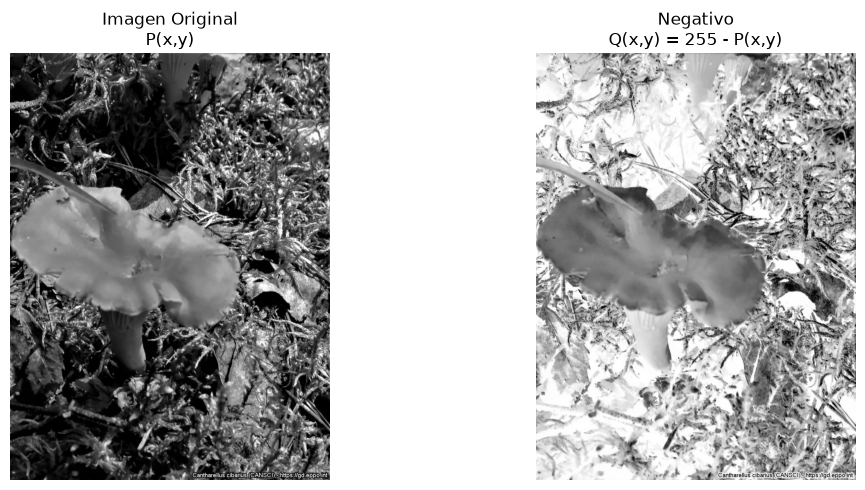

In [31]:
# 1. Cargar la imagen de prueba en escala de grises (Comilla corregida al final)
img_in_negativo = cv2.imread('./Imagenes/Salida/imagen_gris_descargada.jpg', cv2.IMREAD_GRAYSCALE)

# 2. Aplicar el operador negativo
img_out_negativo = operador_negativo(img_in_negativo)

# --- 3. Mostrar los resultados ---
fig_neg, axs_neg = plt.subplots(1, 2, figsize=(12, 5))

# Usamos vmin=0 y vmax=255 para forzar a matplotlib a usar la escala completa
axs_neg[0].imshow(img_in_negativo, cmap='gray', vmin=0, vmax=255)
axs_neg[0].set_title('Imagen Original\nP(x,y)')
axs_neg[0].axis('off')

axs_neg[1].imshow(img_out_negativo, cmap='gray', vmin=0, vmax=255)
axs_neg[1].set_title('Negativo\nQ(x,y) = 255 - P(x,y)')
axs_neg[1].axis('off')

plt.tight_layout()
plt.show()

Descarga de imagenes y matrices

In [33]:
# --- 0. Crear los directorios si no existen para evitar errores ---
os.makedirs('Imagenes/Salida', exist_ok=True)
os.makedirs('Matrices/Salida', exist_ok=True)

# Definimos las rutas exactas que solicitaste

ruta_img_neg_salida = 'Imagenes/Salida/resultado_operador_negativo.png'

ruta_mat_neg_salida = 'Matrices/Salida/matriz_q_negativo.csv'

# --- 1. Guardar las imágenes generadas ---
cv2.imwrite(ruta_img_neg_salida, img_out_negativo)
print("Imágenes del proceso negativo listas y guardadas en 'Imagenes/Salida/'.")

# --- 2. Guardar las matrices numéricas ---
np.savetxt(ruta_mat_neg_salida, img_out_negativo, delimiter=',', fmt='%d')
print("Matrices CSV del proceso negativo listas y guardadas en 'Matrices/Salida/'.")

Imágenes del proceso negativo listas y guardadas en 'Imagenes/Salida/'.
Matrices CSV del proceso negativo listas y guardadas en 'Matrices/Salida/'.


#### Declaración Elongacion y reduccion de contraste

In [34]:
def operador_contraste(matriz_pixel_p, gamma, constante_b, operacion):
    """
    Modifica el contraste de una imagen mediante elongación o reducción.
    operacion: 'elongacion' o 'reduccion'
    """
    # Convertimos a float32 para manejar multiplicaciones y divisiones con precisión
    matriz_p = matriz_pixel_p.astype(np.float32)
    
    if operacion == 'elongacion':
        # Fórmula: Q(x,y) = P(x,y) * gamma + B
        matriz_q = (matriz_p * gamma) + constante_b
        
    elif operacion == 'reduccion':
        # Fórmula: Q(x,y) = P(x,y) / gamma - B
        # Evitamos la división por cero por seguridad
        if gamma == 0:
            raise ValueError("El factor gamma no puede ser 0 para la reducción.")
        matriz_q = (matriz_p / gamma) - constante_b
        
    else:
        raise ValueError("La operación debe ser 'elongacion' o 'reduccion'")
    
    # Recortamos los valores para que no salgan del rango 0-255
    matriz_q = np.clip(matriz_q, 0, 255)
    
    # Regresamos a enteros de 8 bits
    return matriz_q.astype(np.uint8)

#### Ejecucion y visualización

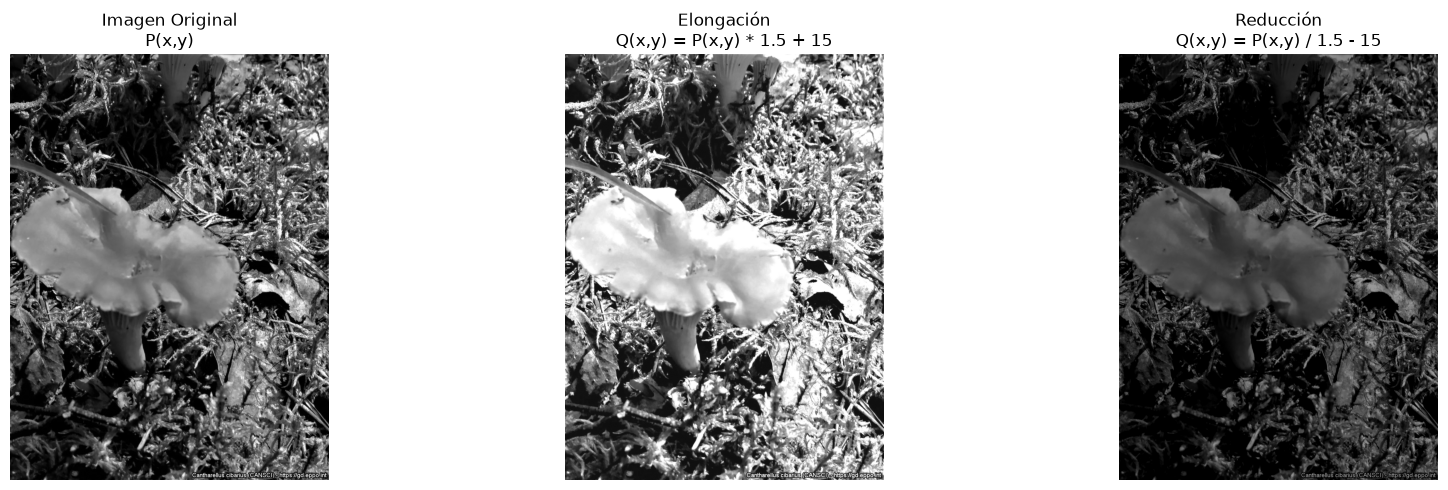

In [35]:
# 1. Cargar la imagen de prueba en escala de grises
ruta_entrada = './Imagenes/Salida/imagen_gris_descargada.jpg'
img_in_contraste = cv2.imread(ruta_entrada, cv2.IMREAD_GRAYSCALE)

# Definir los parámetros (puedes ajustar estos valores según lo que pida tu profesor)
valor_gamma = 1.5
valor_b = 15

# 2. Aplicar los operadores
img_elongada = operador_contraste(img_in_contraste, valor_gamma, valor_b, operacion='elongacion')
img_reducida = operador_contraste(img_in_contraste, valor_gamma, valor_b, operacion='reduccion')

# --- 3. Mostrar los resultados ---
fig_cont, axs_cont = plt.subplots(1, 3, figsize=(18, 5))

axs_cont[0].imshow(img_in_contraste, cmap='gray', vmin=0, vmax=255)
axs_cont[0].set_title('Imagen Original\nP(x,y)')
axs_cont[0].axis('off')

axs_cont[1].imshow(img_elongada, cmap='gray', vmin=0, vmax=255)
axs_cont[1].set_title(f'Elongación\nQ(x,y) = P(x,y) * {valor_gamma} + {valor_b}') #[cite: 5]
axs_cont[1].axis('off')

axs_cont[2].imshow(img_reducida, cmap='gray', vmin=0, vmax=255)
axs_cont[2].set_title(f'Reducción\nQ(x,y) = P(x,y) / {valor_gamma} - {valor_b}') #[cite: 5]
axs_cont[2].axis('off')

plt.tight_layout()
plt.show()

Descargar imagenes y matrices correspondientes

In [36]:
# --- 0. Asegurar que los directorios existan ---
os.makedirs('Imagenes/Salida', exist_ok=True)
os.makedirs('Matrices/Salida', exist_ok=True)

# Rutas para las imágenes
ruta_img_elong = 'Imagenes/Salida/resultado_contraste_elongacion.png'
ruta_img_reduc = 'Imagenes/Salida/resultado_contraste_reduccion.png'

# Rutas para las matrices
ruta_mat_elong = 'Matrices/Salida/matriz_contraste_elongacion.csv'
ruta_mat_reduc = 'Matrices/Salida/matriz_contraste_reduccion.csv'

# --- 1. Guardar las imágenes generadas ---
cv2.imwrite(ruta_img_elong, img_elongada)
cv2.imwrite(ruta_img_reduc, img_reducida)
print("Imágenes del proceso de contraste guardadas en 'Imagenes/Salida/'.")

# --- 2. Guardar las matrices numéricas ---
np.savetxt(ruta_mat_elong, img_elongada, delimiter=',', fmt='%d')
np.savetxt(ruta_mat_reduc, img_reducida, delimiter=',', fmt='%d')
print("Matrices CSV del proceso de contraste guardadas en 'Matrices/Salida/'.")

Imágenes del proceso de contraste guardadas en 'Imagenes/Salida/'.
Matrices CSV del proceso de contraste guardadas en 'Matrices/Salida/'.


#### Declaración de la Función de Shifting H/V/D

In [37]:
def operador_shifting(matriz_pixel_p, dx, dy):
    """
    Desplaza la imagen en los ejes X (Horizontal) y Y (Vertical).
    - dx: Desplazamiento horizontal (positivo = derecha, negativo = izquierda)
    - dy: Desplazamiento vertical (positivo = abajo, negativo = arriba)
    """
    # Obtenemos las dimensiones de la imagen (filas/alto y columnas/ancho)
    filas, columnas = matriz_pixel_p.shape[:2]
    
    # Creamos la matriz de transformación de traslación (2x3)
    # [1, 0, dx] -> Controla el eje X
    # [0, 1, dy] -> Controla el eje Y
    matriz_transformacion_M = np.float32([
        [1, 0, dx],
        [0, 1, dy]
    ])
    
    # Aplicamos la transformación espacial con warpAffine
    # Los espacios vacíos que deje el desplazamiento se llenarán de negro (0) por defecto
    matriz_q = cv2.warpAffine(matriz_pixel_p, matriz_transformacion_M, (columnas, filas))
    
    return matriz_q

#### Ejecución y Visualización

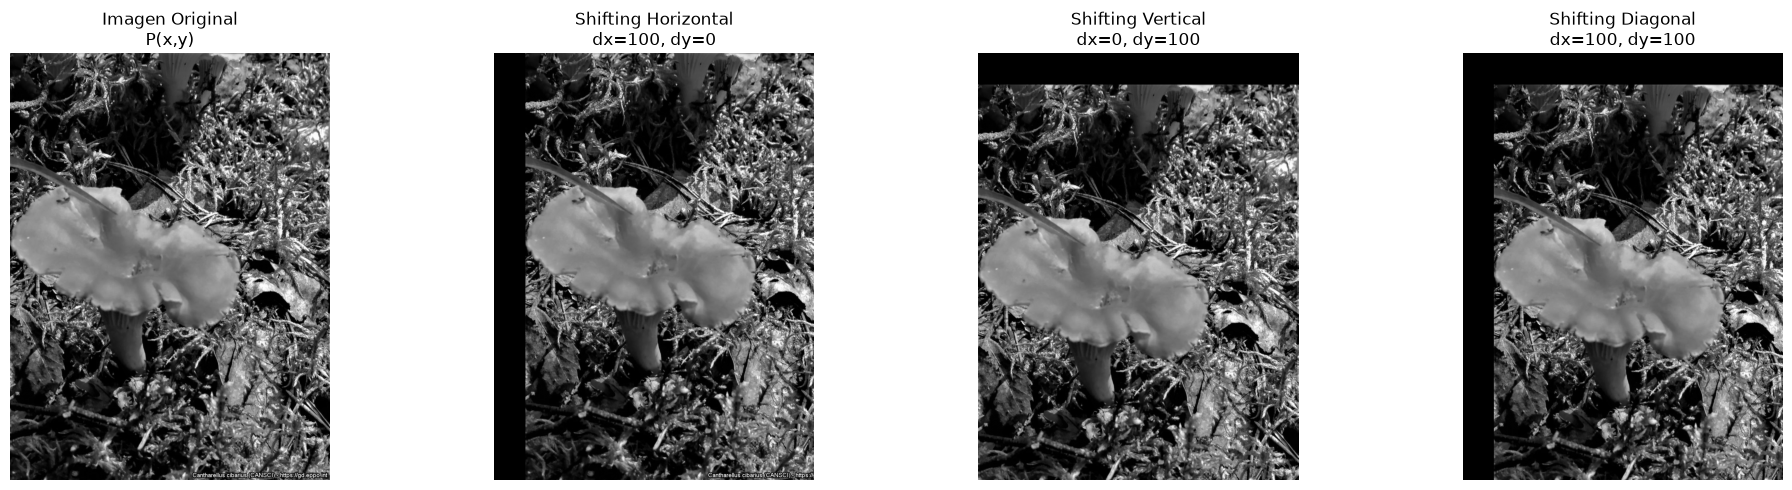

In [38]:
# 1. Cargar la imagen de prueba en escala de grises
ruta_entrada_shift = './Imagenes/Salida/imagen_gris_descargada.jpg'
img_in_shifting = cv2.imread(ruta_entrada_shift, cv2.IMREAD_GRAYSCALE)

# Definir la cantidad de píxeles a desplazar
desplazamiento = 100

# 2. Aplicar los operadores H, V y D
# Horizontal (dx = 100, dy = 0)
img_shift_h = operador_shifting(img_in_shifting, dx=desplazamiento, dy=0)

# Vertical (dx = 0, dy = 100)
img_shift_v = operador_shifting(img_in_shifting, dx=0, dy=desplazamiento)

# Diagonal (dx = 100, dy = 100)
img_shift_d = operador_shifting(img_in_shifting, dx=desplazamiento, dy=desplazamiento)

# --- 3. Mostrar los resultados ---
fig_shift, axs_shift = plt.subplots(1, 4, figsize=(20, 5))

axs_shift[0].imshow(img_in_shifting, cmap='gray', vmin=0, vmax=255)
axs_shift[0].set_title('Imagen Original\nP(x,y)')
axs_shift[0].axis('off')

axs_shift[1].imshow(img_shift_h, cmap='gray', vmin=0, vmax=255)
axs_shift[1].set_title(f'Shifting Horizontal\ndx={desplazamiento}, dy=0')
axs_shift[1].axis('off')

axs_shift[2].imshow(img_shift_v, cmap='gray', vmin=0, vmax=255)
axs_shift[2].set_title(f'Shifting Vertical\ndx=0, dy={desplazamiento}')
axs_shift[2].axis('off')

axs_shift[3].imshow(img_shift_d, cmap='gray', vmin=0, vmax=255)
axs_shift[3].set_title(f'Shifting Diagonal\ndx={desplazamiento}, dy={desplazamiento}')
axs_shift[3].axis('off')

plt.tight_layout()
plt.show()

Descargar la imagen y la matriz

In [39]:
# --- 0. Asegurar que los directorios existan ---
os.makedirs('Imagenes/Salida', exist_ok=True)
os.makedirs('Matrices/Salida', exist_ok=True)

# Definir rutas para las imágenes
ruta_img_h = 'Imagenes/Salida/resultado_shifting_h.png'
ruta_img_v = 'Imagenes/Salida/resultado_shifting_v.png'
ruta_img_d = 'Imagenes/Salida/resultado_shifting_d.png'

# Definir rutas para las matrices CSV
ruta_mat_h = 'Matrices/Salida/matriz_shifting_h.csv'
ruta_mat_v = 'Matrices/Salida/matriz_shifting_v.csv'
ruta_mat_d = 'Matrices/Salida/matriz_shifting_d.csv'

# --- 1. Guardar las imágenes generadas ---
cv2.imwrite(ruta_img_h, img_shift_h)
cv2.imwrite(ruta_img_v, img_shift_v)
cv2.imwrite(ruta_img_d, img_shift_d)
print("Imágenes del proceso de Shifting H/V/D guardadas en 'Imagenes/Salida/'.")

# --- 2. Guardar las matrices numéricas ---
np.savetxt(ruta_mat_h, img_shift_h, delimiter=',', fmt='%d')
np.savetxt(ruta_mat_v, img_shift_v, delimiter=',', fmt='%d')
np.savetxt(ruta_mat_d, img_shift_d, delimiter=',', fmt='%d')
print("Matrices CSV del proceso de Shifting H/V/D guardadas en 'Matrices/Salida/'.")

Imágenes del proceso de Shifting H/V/D guardadas en 'Imagenes/Salida/'.
Matrices CSV del proceso de Shifting H/V/D guardadas en 'Matrices/Salida/'.


#### Definicion de función Aclaramiento/ oscurecimiento

In [41]:
def operador_asignacion_a(matriz_pixel_p, constante_a):
    """
    Aplica la fórmula P(X,Y) = A para el aclarado/oscurecimiento.
    Reemplaza todos los valores de la imagen con la constante A.
    """
    # Aseguramos que el valor A esté en el rango permitido de 8 bits (0-255)
    valor_a = np.clip(constante_a, 0, 255)
    
    # Creamos una nueva matriz del mismo tamaño que la original, 
    # pero llenamos todos sus espacios exclusivamente con el valor de la constante A
    matriz_q = np.full(matriz_pixel_p.shape, valor_a, dtype=np.uint8)
    
    return matriz_q

#### Ejecución y resultados

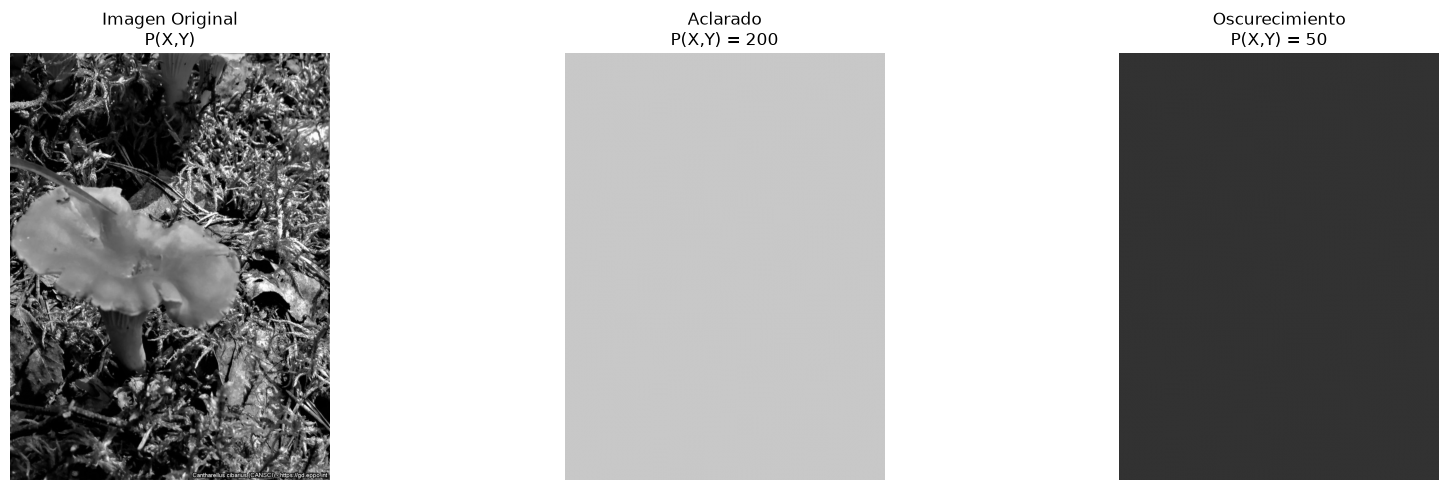

In [42]:
# 1. Cargar la imagen original en escala de grises
ruta_entrada_a = './Imagenes/Salida/imagen_gris_descargada.jpg'
img_in_a = cv2.imread(ruta_entrada_a, cv2.IMREAD_GRAYSCALE)

# 2. Definir los valores de la constante A
# Un valor alto para Aclarado y uno bajo para Oscurecimiento
valor_a_aclarado = 200
valor_a_oscurecido = 50

# 3. Aplicar el operador
img_aclarado_a = operador_asignacion_a(img_in_a, valor_a_aclarado)
img_oscurecido_a = operador_asignacion_a(img_in_a, valor_a_oscurecido)

# --- 4. Mostrar los resultados ---
fig_a, axs_a = plt.subplots(1, 3, figsize=(18, 5))

axs_a[0].imshow(img_in_a, cmap='gray', vmin=0, vmax=255)
axs_a[0].set_title('Imagen Original\nP(X,Y)')
axs_a[0].axis('off')

# Mostramos el Aclarado
axs_a[1].imshow(img_aclarado_a, cmap='gray', vmin=0, vmax=255)
axs_a[1].set_title(f'Aclarado\nP(X,Y) = {valor_a_aclarado}') #[cite: 7]
axs_a[1].axis('off')

# Mostramos el Oscurecimiento
axs_a[2].imshow(img_oscurecido_a, cmap='gray', vmin=0, vmax=255)
axs_a[2].set_title(f'Oscurecimiento\nP(X,Y) = {valor_a_oscurecido}') #[cite: 7]
axs_a[2].axis('off')

plt.tight_layout()
plt.show()

Descarga de Imagenes y matrices

In [43]:
# --- 0. Asegurar que los directorios existan ---
os.makedirs('Imagenes/Salida', exist_ok=True)
os.makedirs('Matrices/Salida', exist_ok=True)

# Definir rutas para las imágenes
ruta_img_a_aclarado = 'Imagenes/Salida/resultado_a_aclarado.png'
ruta_img_a_oscurecido = 'Imagenes/Salida/resultado_a_oscurecido.png'

# Definir rutas para las matrices CSV
ruta_mat_a_aclarado = 'Matrices/Salida/matriz_a_aclarado.csv'
ruta_mat_a_oscurecido = 'Matrices/Salida/matriz_a_oscurecido.csv'

# --- 1. Guardar las imágenes generadas ---
cv2.imwrite(ruta_img_a_aclarado, img_aclarado_a)
cv2.imwrite(ruta_img_a_oscurecido, img_oscurecido_a)
print("Imágenes del proceso de asignación P(X,Y)=A guardadas en 'Imagenes/Salida/'.")

# --- 2. Guardar las matrices numéricas ---
np.savetxt(ruta_mat_a_aclarado, img_aclarado_a, delimiter=',', fmt='%d')
np.savetxt(ruta_mat_a_oscurecido, img_oscurecido_a, delimiter=',', fmt='%d')
print("Matrices CSV del proceso de asignación P(X,Y)=A guardadas en 'Matrices/Salida/'.")

Imágenes del proceso de asignación P(X,Y)=A guardadas en 'Imagenes/Salida/'.
Matrices CSV del proceso de asignación P(X,Y)=A guardadas en 'Matrices/Salida/'.
